# Lab 1.2 - Image Classification with PyTorch (Solution)
**Day 1 - Session 2**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kpassoubady/gen-ai-companion-intuite/blob/main/day1/lab1_2_image_clf/solution/lab1_2_image_clf.ipynb)

**Goal:** Build, train, and evaluate a neural network that classifies clothing
images from the FashionMNIST dataset.

The dataset and epochs are capped so every cell finishes in a couple of minutes
on a Colab CPU runtime. No GPU needed.

In [1]:
# Scoped install for this lab (safe to re-run; preinstalled on Colab).
%pip install -q torch torchvision matplotlib

In [2]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cpu


## 1. Load a small slice of FashionMNIST
We use 6,000 training images and 1,000 test images so training stays fast on
CPU. Each image is 28x28 grayscale, and there are 10 clothing classes.

In [3]:
transform = transforms.ToTensor()
train_full = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
test_full = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)

train_ds = Subset(train_full, range(6000))
test_ds = Subset(test_full, range(1000))
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=256)

classes = train_full.classes
print("Train images:", len(train_ds), "| Test images:", len(test_ds))
print("Classes:", classes)

100%|██████████| 26.4M/26.4M [00:01<00:00, 18.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 272kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.07MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 10.9MB/s]

Train images: 6000 | Test images: 1000
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


## 2. Peek at the data
Always look at a few examples before training.

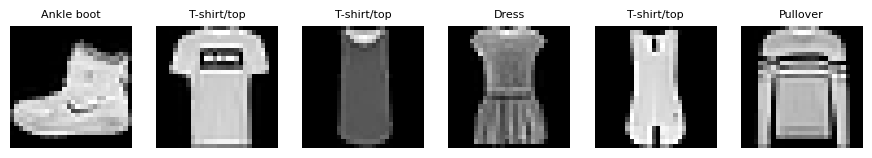

In [4]:
fig, axes = plt.subplots(1, 6, figsize=(11, 2))
for ax, (img, label) in zip(axes, train_ds):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(classes[label], fontsize=8)
    ax.axis("off")
plt.show()

## 3. Build the network
A small feedforward network: flatten the image, one hidden layer with ReLU,
then a 10-way output.

In [5]:
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10),
).to(device)
print(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=10, bias=True)
)


## 4. Train
We use cross-entropy loss and the Adam optimizer for 3 epochs.

In [6]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(3):
    model.train()
    running = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(images), labels)
        loss.backward()
        optimizer.step()
        running += loss.item()
    print(f"epoch {epoch + 1}: avg loss {running / len(train_loader):.4f}")

epoch 1: avg loss 0.9883
epoch 2: avg loss 0.6148
epoch 3: avg loss 0.5213


## 5. Evaluate on the test set
Switch to eval mode and turn off gradients for a clean accuracy measurement.

In [7]:
model.eval()
correct = total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        predicted = model(images).argmax(dim=1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
print(f"Test accuracy: {correct / total:.3f}")

Test accuracy: 0.815


## Stretch goals
1. Add a second hidden layer (for example 128 -> 64 -> 10) and compare accuracy.
2. Replace the flatten+linear stack with a small convolutional network
   (`nn.Conv2d`) and see how much accuracy improves.

In [8]:
# Stretch 1: a deeper feedforward network.
deeper = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 10),
).to(device)
opt2 = torch.optim.Adam(deeper.parameters(), lr=1e-3)
for epoch in range(3):
    deeper.train()
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        opt2.zero_grad()
        loss_fn(deeper(images), labels).backward()
        opt2.step()

deeper.eval()
correct = total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        correct += (deeper(images).argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
print(f"Deeper network test accuracy: {correct / total:.3f}")

Deeper network test accuracy: 0.829


### Expected output
- Training loss drops each epoch.
- The one-hidden-layer network reaches roughly 0.82-0.86 test accuracy on this
  small slice.
- The deeper network lands in a similar range; convolutional models
  (stretch goal 2) usually do best.